## LexisNexis - Detecting Fraudulent Insurance Claims

### Mukundan Thanigaivelan

In this notebook, we try to determine the most informational features and train logistic regression models.

### Import libraries and data

In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, math

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, average_precision_score, f1_score, confusion_matrix

In [149]:
df = pd.read_csv('cleaned_fraud_oracle.csv')
df.shape

(15420, 40)

### Examine numeric features

- Only good numeric features to include:
  + Age
  + Deductible

Otherwise, the text &rarr; number columns are also good.

In [150]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])
numeric_df.shape

(15420, 16)

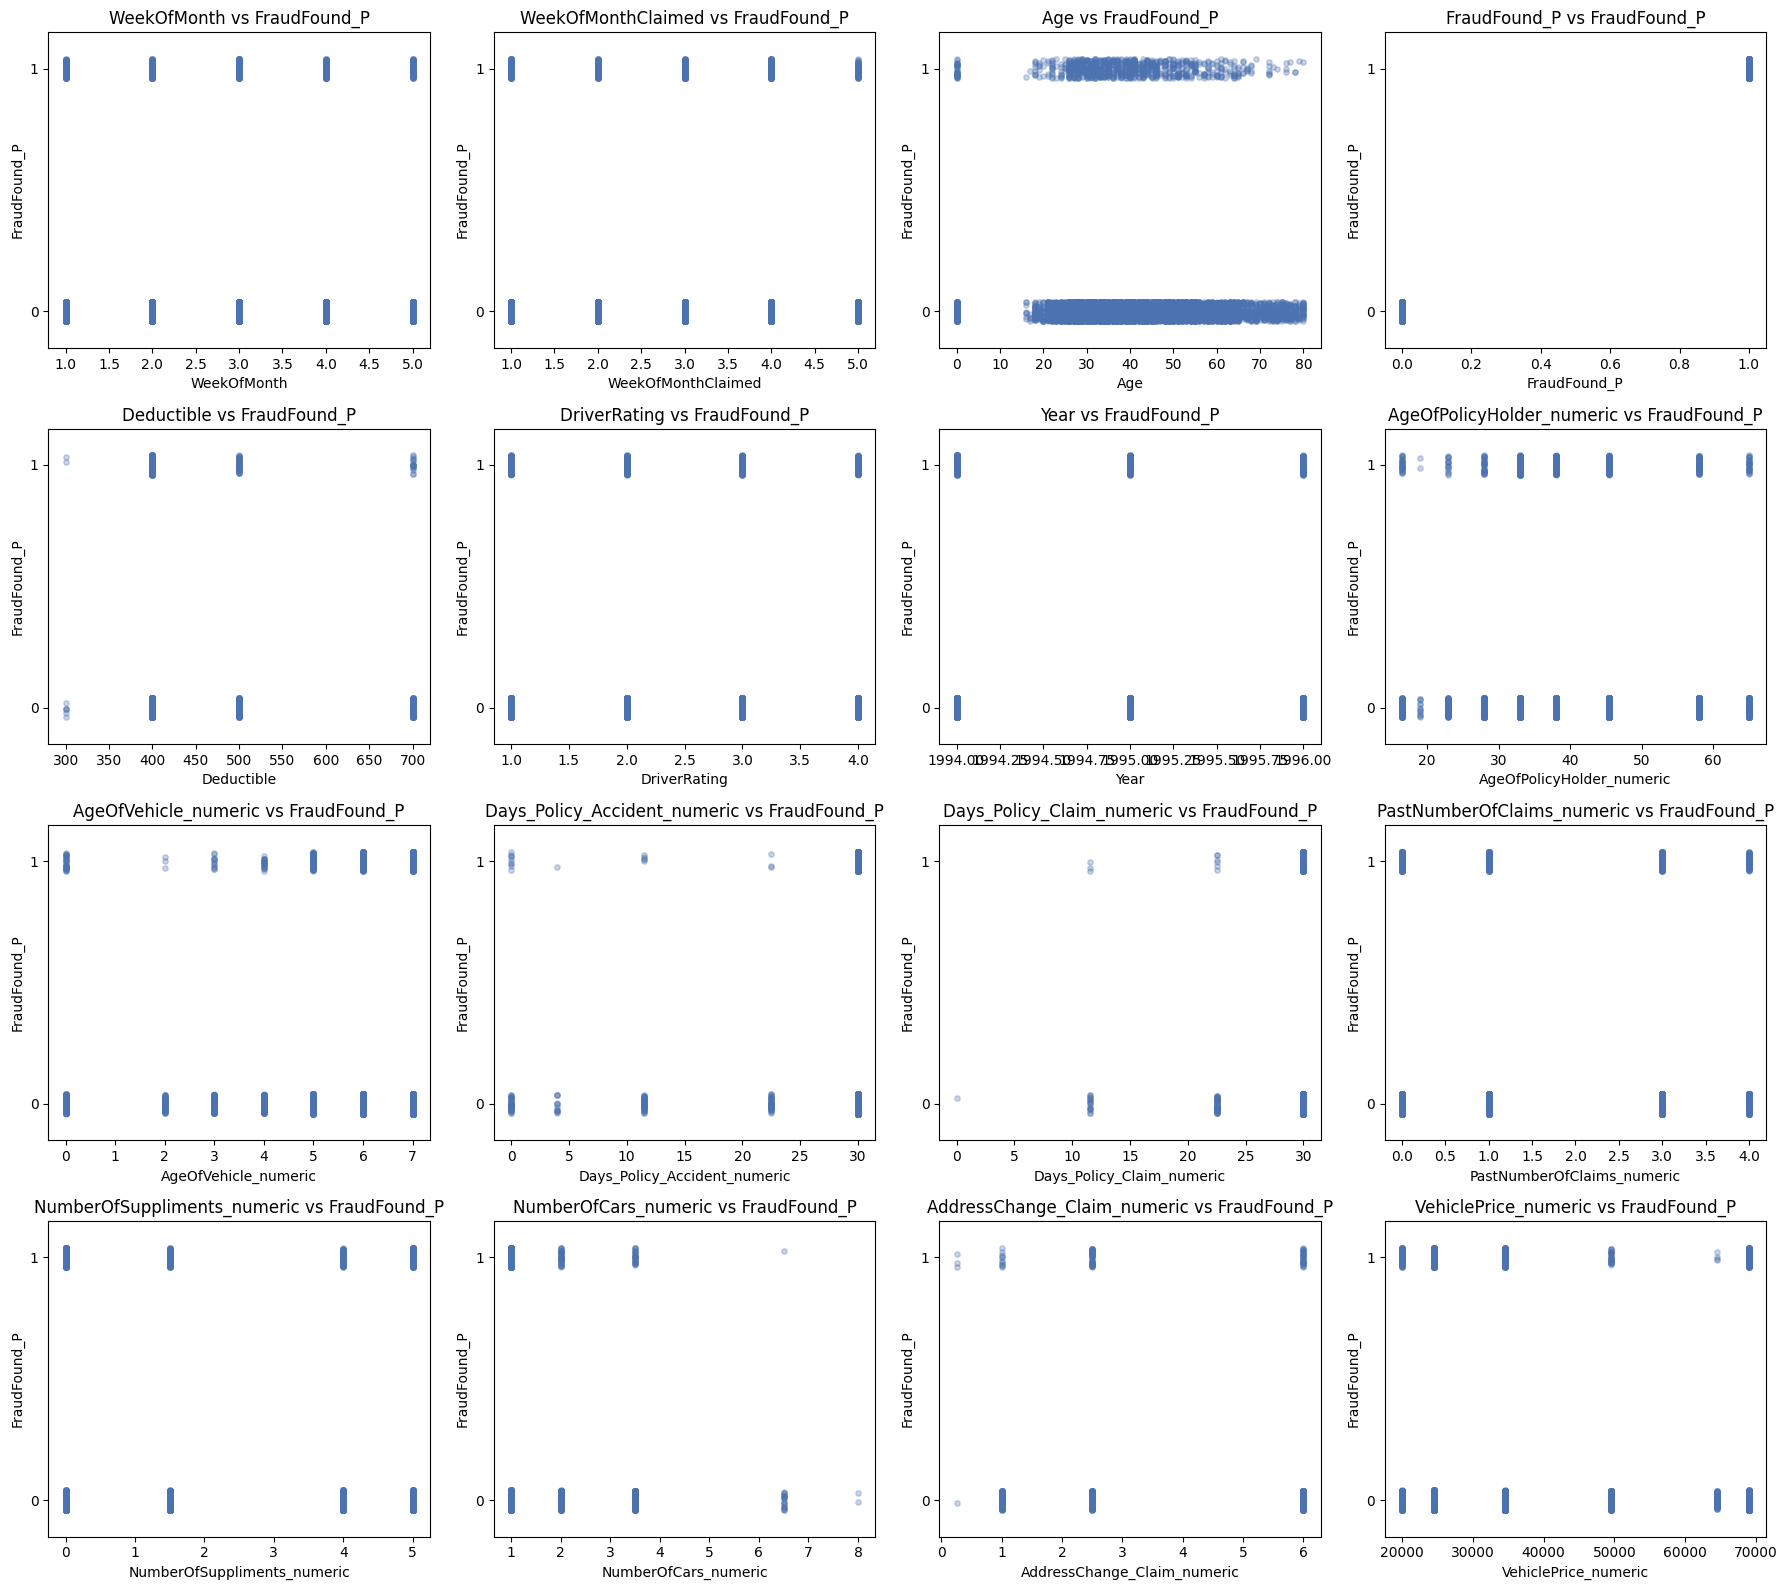

In [151]:
ncols = 4
nrows = math.ceil(len(numeric_df.columns) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_df.columns):
    y_jitter = numeric_df['FraudFound_P'] + np.random.uniform(
        -0.04, 0.04, size=len(df)
    )

    axes[i].scatter(
        numeric_df[col], y_jitter,
        alpha=0.3,
        s=15,
        color='#4C72B0'
    )

    axes[i].set_title(f'{col} vs FraudFound_P')
    axes[i].set_xlabel(col)
    axes[i].set_yticks([0, 1])
    axes[i].set_ylim(-0.15, 1.15)
    axes[i].set_ylabel('FraudFound_P')

for j in range(len(numeric_df.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

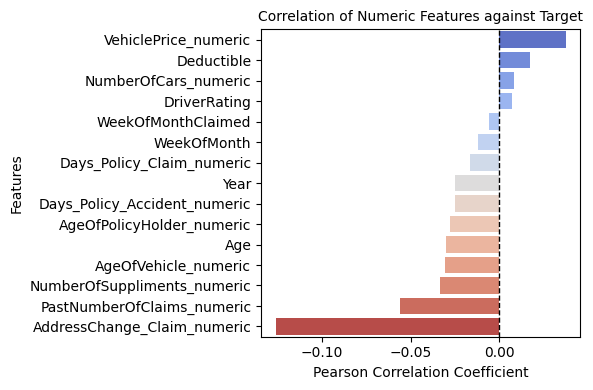

In [152]:
target_corr = numeric_df.corr()['FraudFound_P'].drop('FraudFound_P').sort_values(ascending = False)

plt.figure(figsize=(6, 4))
sns.barplot(
  x = target_corr.values,
  y = target_corr.index,
  hue = target_corr.index,
  legend = False,
  palette = 'coolwarm'
)
plt.axvline(
  x = 0,
  color = 'black',
  linestyle = '--',
  linewidth = 1
)

plt.title('Correlation of Numeric Features against Target', fontsize = 10)
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

<Axes: xlabel='AddressChange_Claim_numeric', ylabel='FraudFound_P'>

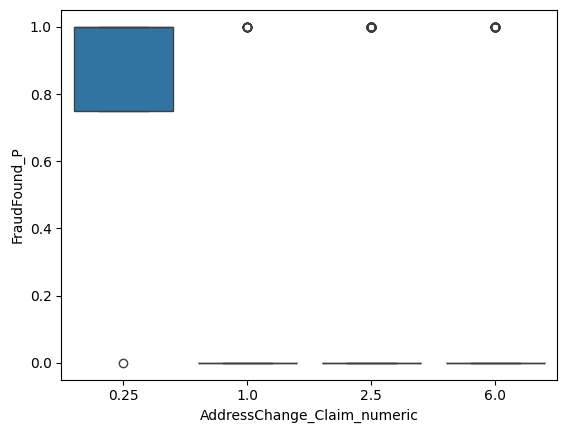

In [153]:
sns.boxplot(
  df,
  x = 'AddressChange_Claim_numeric',
  y = 'FraudFound_P'
)

### Examine categorical features

- Most important categorical features:
  + Make
  + Fault
  + Policy type
  + Vehicle category
  + Agent type
  + Base policy
  + Days policy accident - type
  + Days policy claim - type
  + Number of cars - type
  + Address change claim - type
  + Vehicle price - type

In [154]:
category_df = df.select_dtypes(include = ['O'])
category_df.shape

(15420, 24)

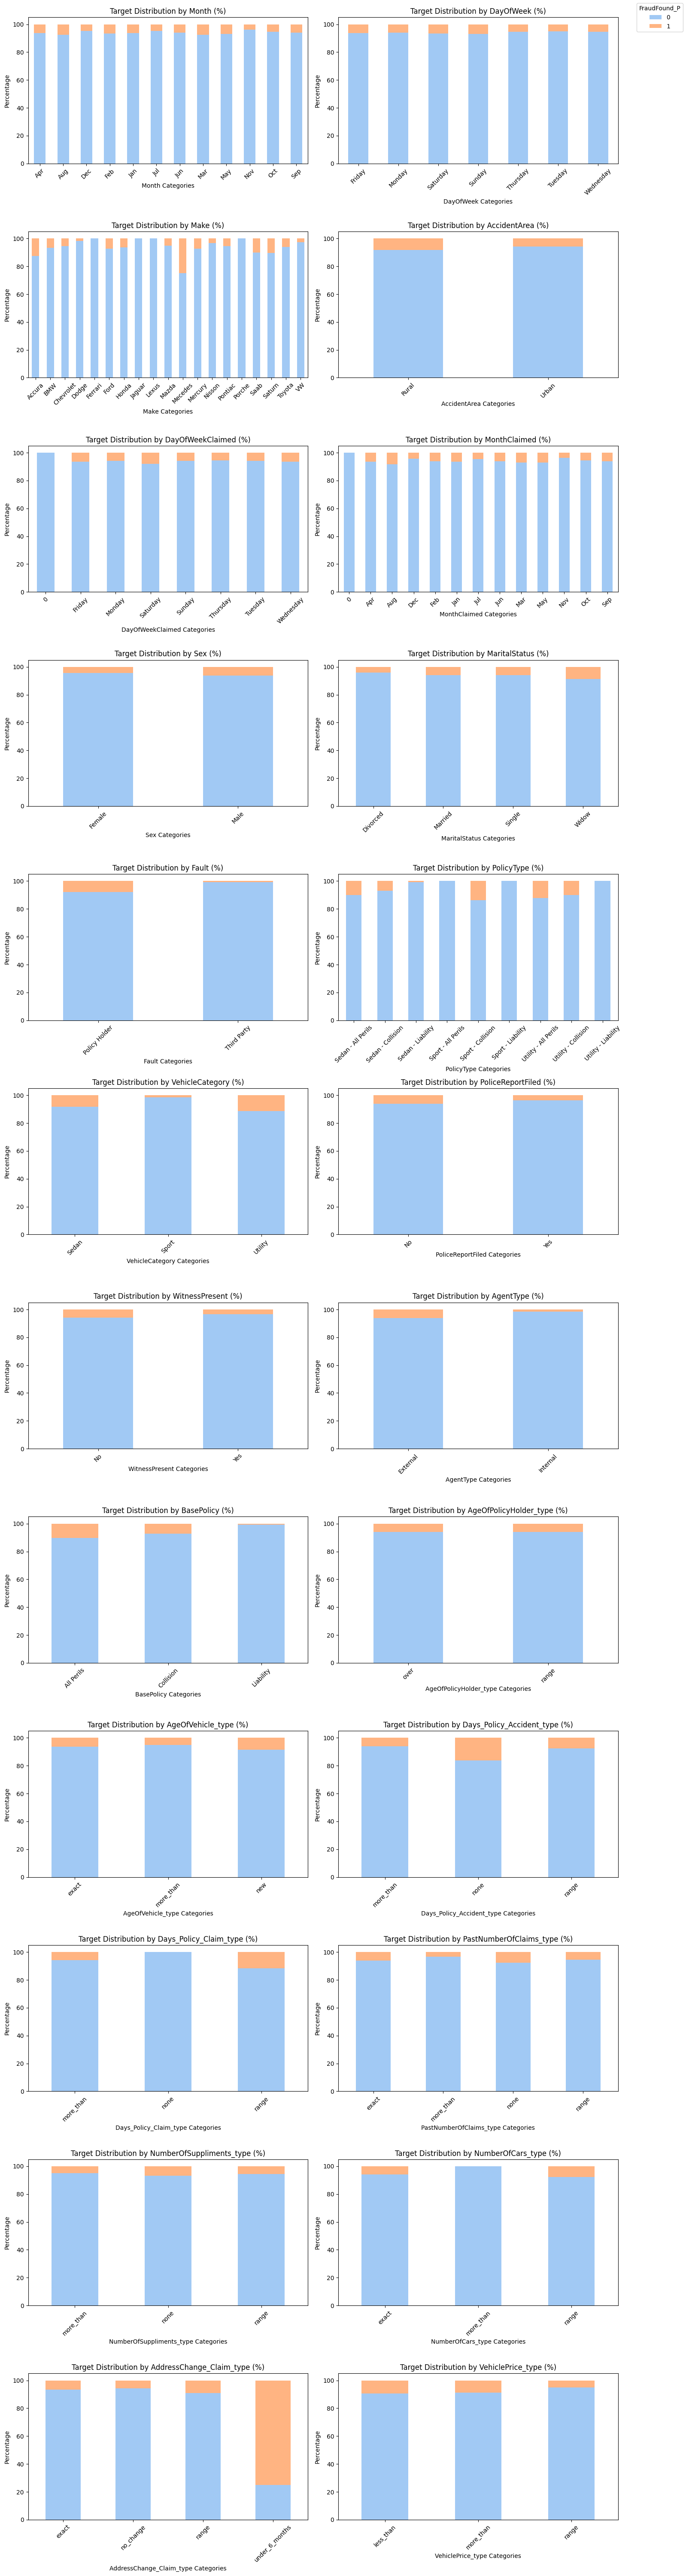

In [155]:
n = len(category_df.columns)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows))
axes = axes.flatten()

for i, col in enumerate(category_df.columns):
  props = pd.crosstab(
    df[col],
    df['FraudFound_P'],
    normalize='index'
  ) * 100

  props.plot(
    kind='bar',
    stacked=True,
    color=['#A1C9F4', '#FFB482'],
    ax=axes[i],
    legend=False
  )

  axes[i].set_title(f'Target Distribution by {col} (%)')
  axes[i].set_ylabel('Percentage')
  axes[i].set_xlabel(f'{col} Categories')
  axes[i].tick_params(axis='x', rotation=45)

for j in range(n, len(axes)):
  fig.delaxes(axes[j])

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='FraudFound_P', loc='upper right')

plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.show()

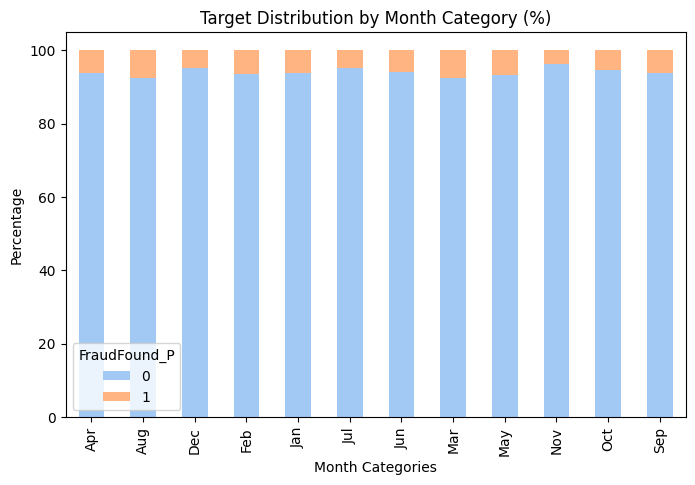

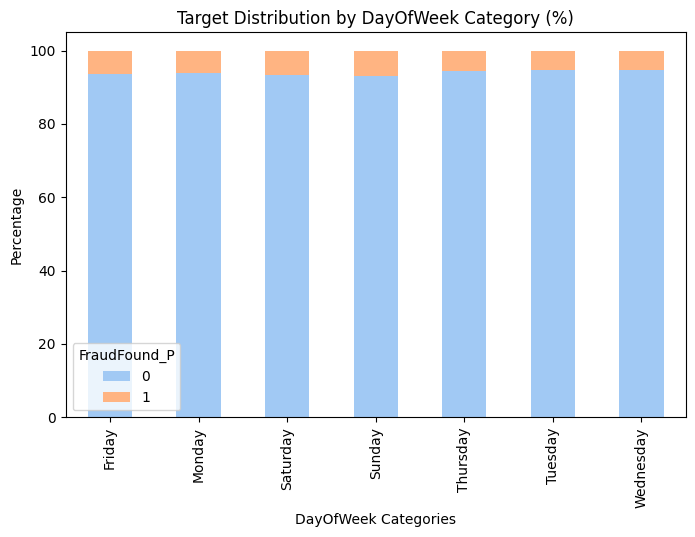

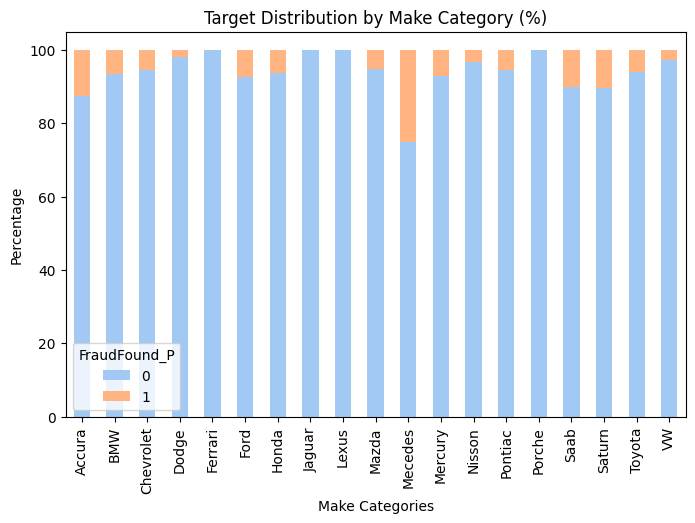

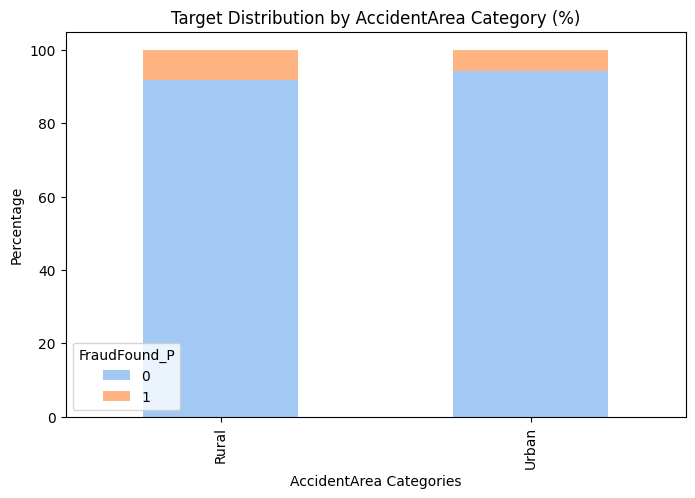

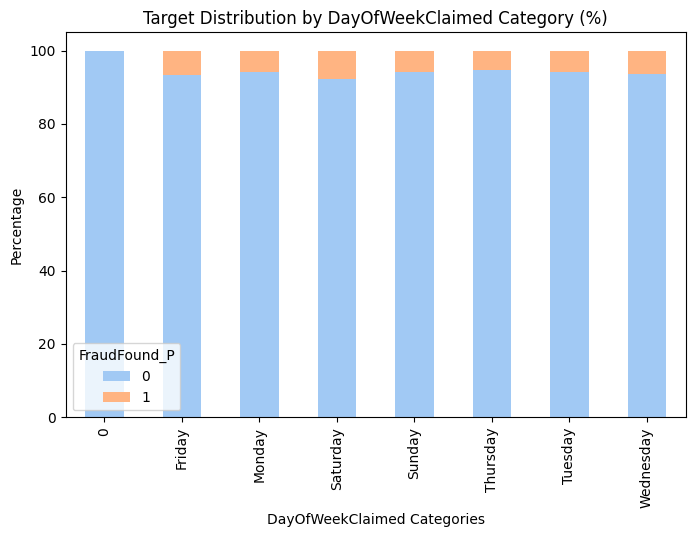

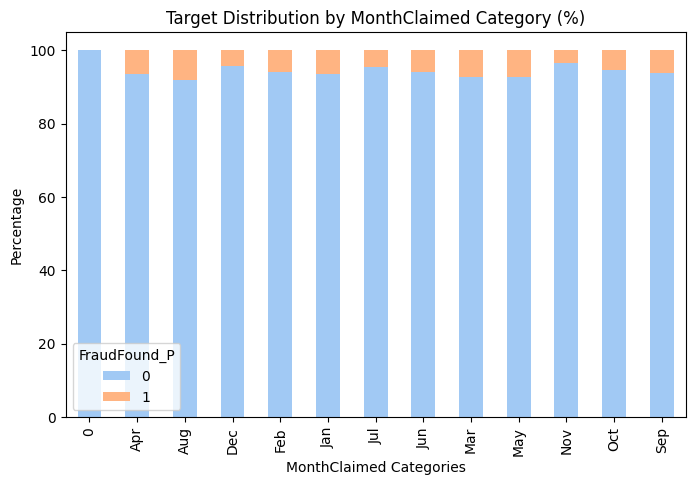

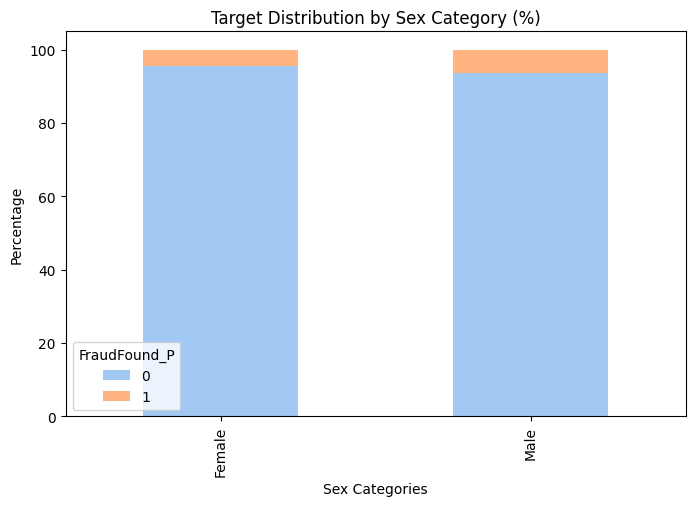

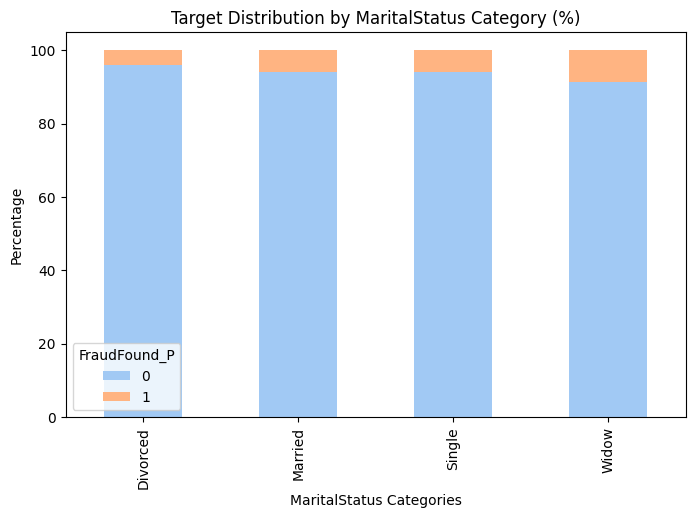

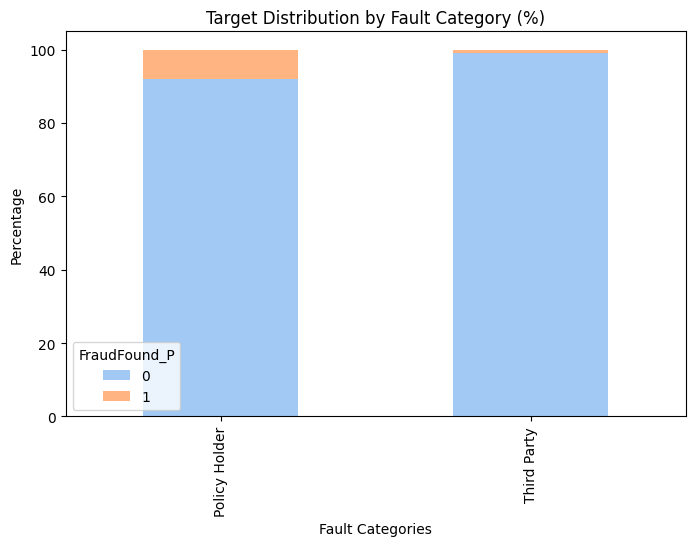

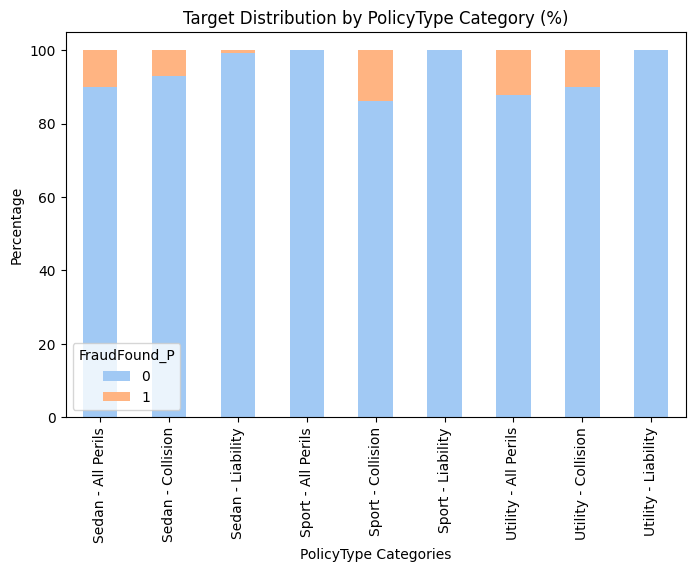

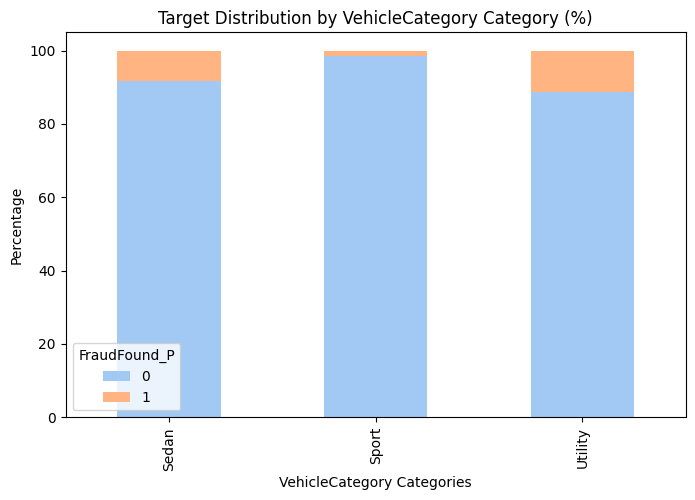

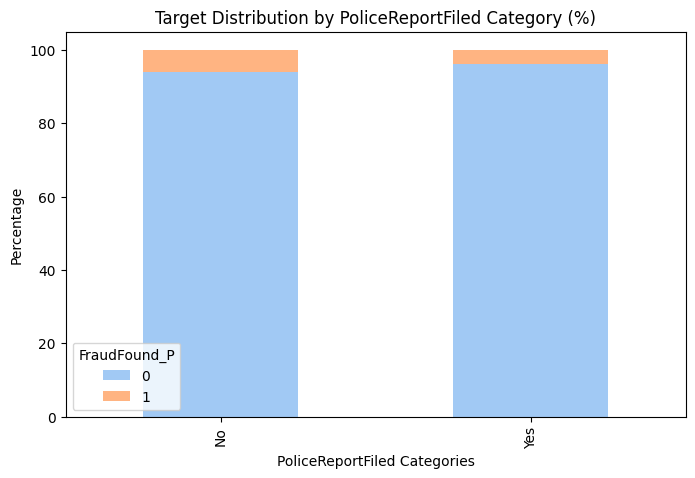

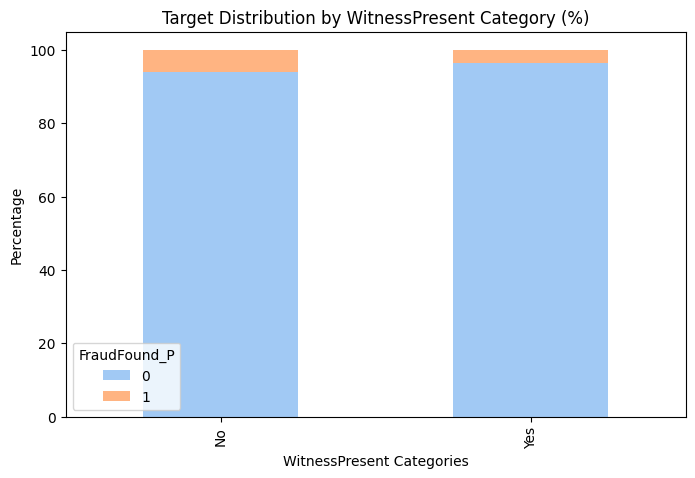

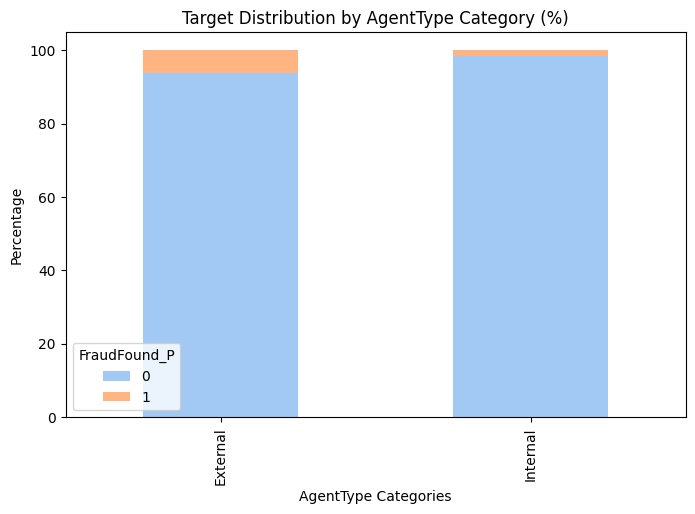

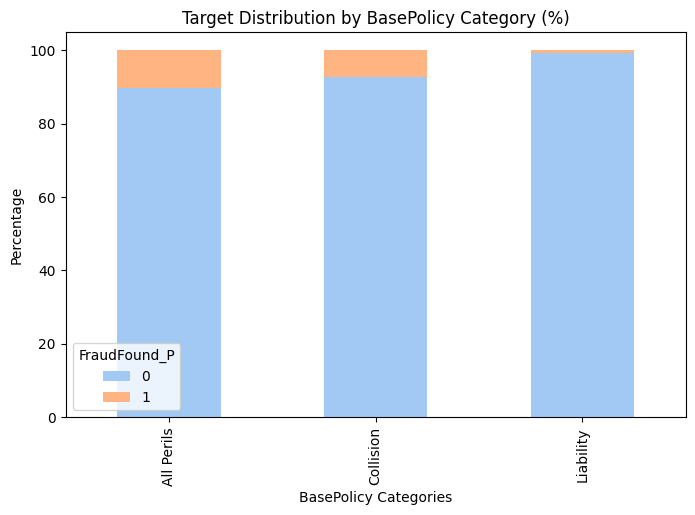

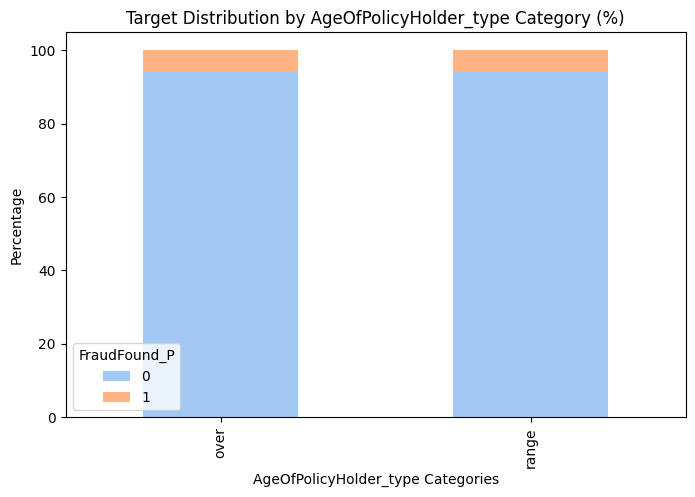

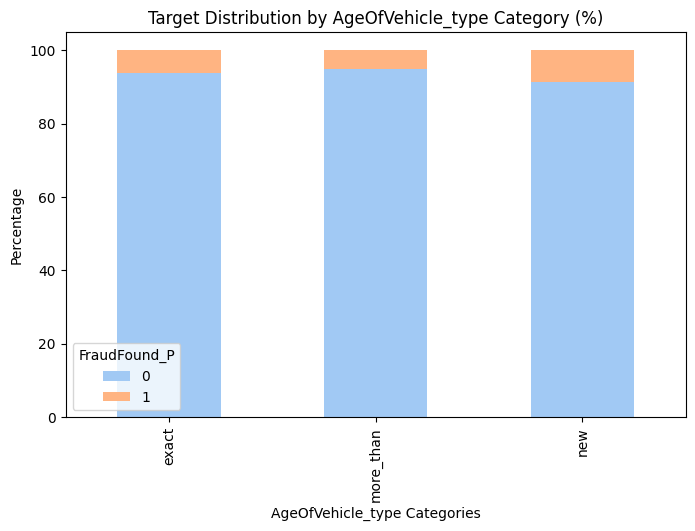

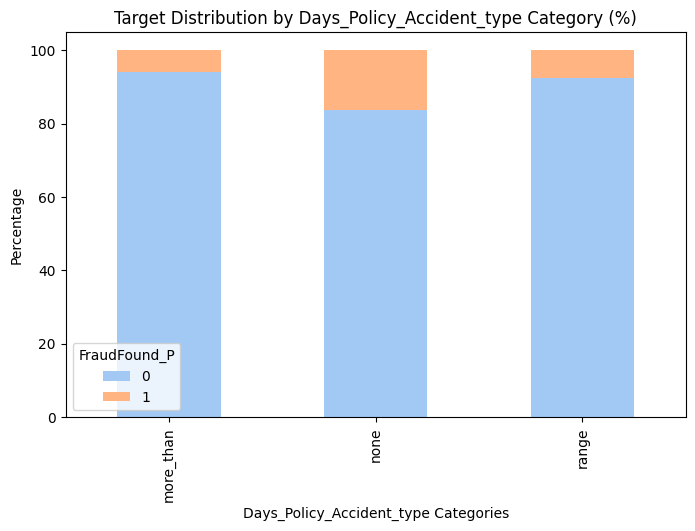

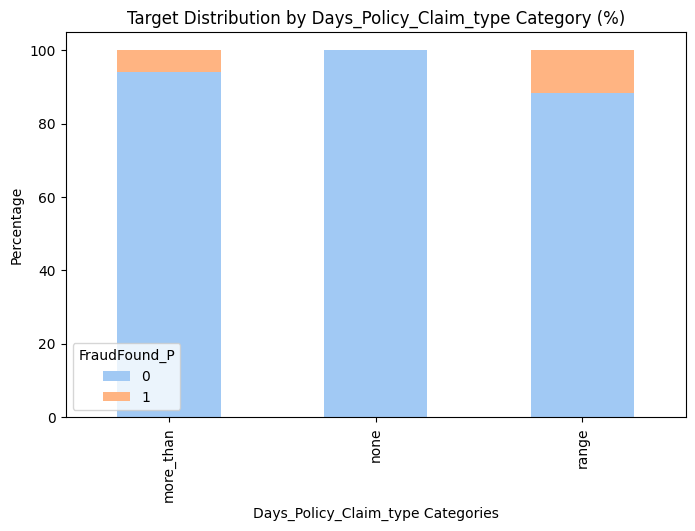

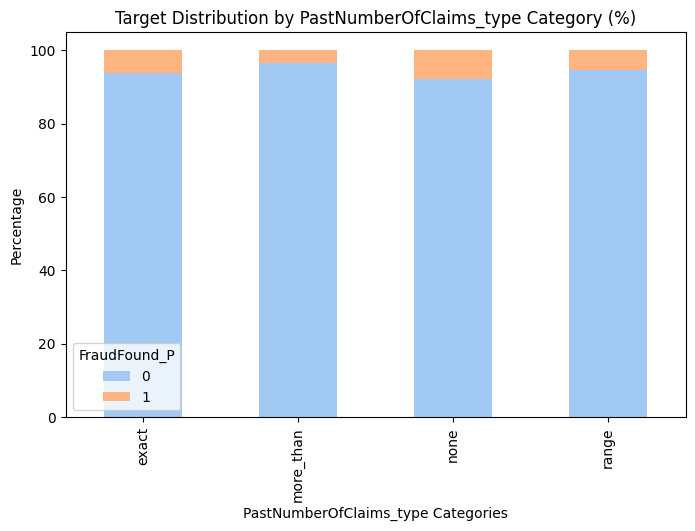

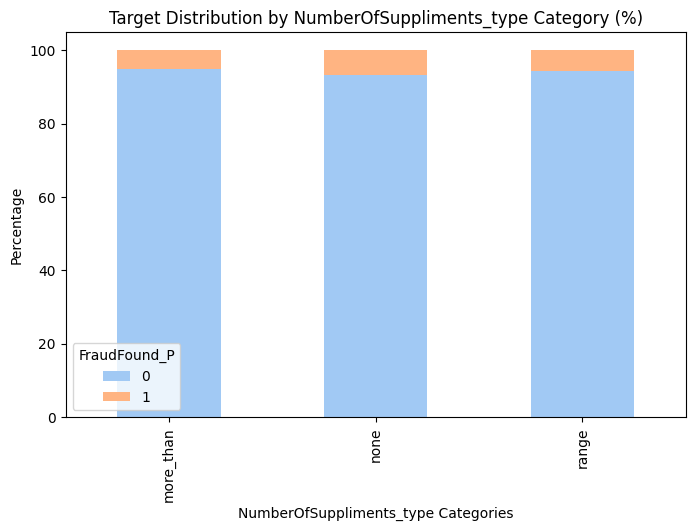

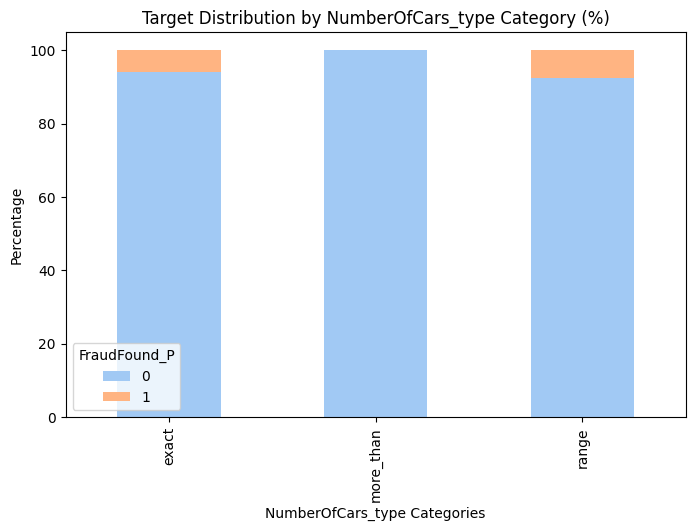

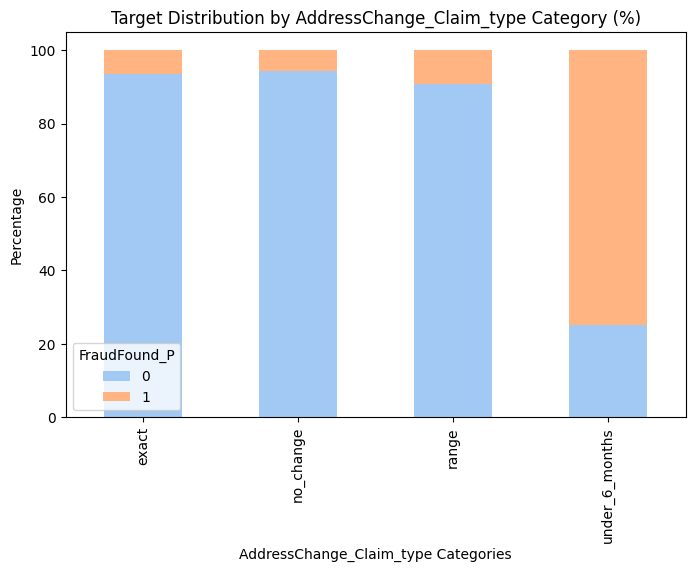

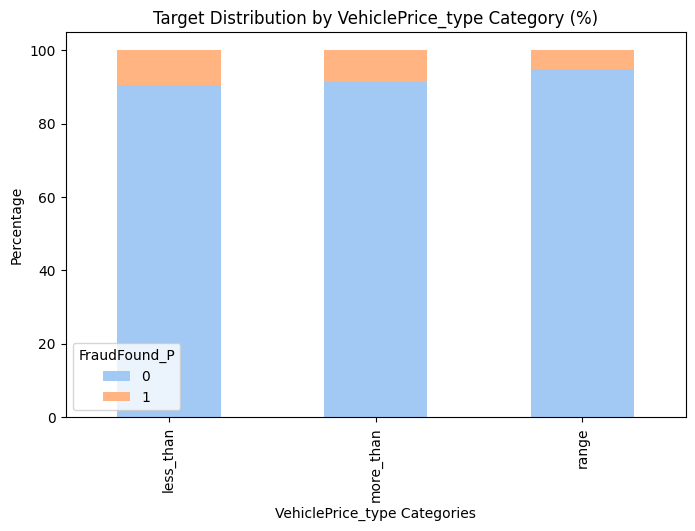

In [156]:
for col in category_df.columns:
  props = pd.crosstab(df[col], df['FraudFound_P'], normalize='index') * 100

  # Plot
  props.plot(kind='bar', stacked=True, color=['#A1C9F4', '#FFB482'], figsize=(8, 5))
  plt.title(f'Target Distribution by {col} Category (%)')
  plt.ylabel('Percentage')
  plt.xlabel(f'{col} Categories')
  plt.legend(title='FraudFound_P', loc='lower left')
  plt.show()

In [157]:
df.columns

Index(['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea',
       'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex',
       'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory',
       'FraudFound_P', 'Deductible', 'DriverRating', 'PoliceReportFiled',
       'WitnessPresent', 'AgentType', 'Year', 'BasePolicy',
       'AgeOfPolicyHolder_numeric', 'AgeOfPolicyHolder_type',
       'AgeOfVehicle_numeric', 'AgeOfVehicle_type',
       'Days_Policy_Accident_numeric', 'Days_Policy_Accident_type',
       'Days_Policy_Claim_numeric', 'Days_Policy_Claim_type',
       'PastNumberOfClaims_numeric', 'PastNumberOfClaims_type',
       'NumberOfSuppliments_numeric', 'NumberOfSuppliments_type',
       'NumberOfCars_numeric', 'NumberOfCars_type',
       'AddressChange_Claim_numeric', 'AddressChange_Claim_type',
       'VehiclePrice_numeric', 'VehiclePrice_type'],
      dtype='object')

### Save the filtered data

In [158]:
filtered_df = df[
  [
    'Age',
    'Deductible',
    'Make',
    'Fault',
    'PolicyType',
    'VehicleCategory',
    'AgentType',
    'BasePolicy',
    'Days_Policy_Accident_type',
    'Days_Policy_Claim_type',
    'NumberOfCars_type',
    'AddressChange_Claim_type',
    'VehiclePrice_type',
    'FraudFound_P',
    'Year'
  ]
]
filtered_df.shape

(15420, 15)

In [159]:
filtered_df.to_csv('filtered_feature_engineered_fraud_oracle.csv')

### Logistic Regression (random split)

- Random train-test split
- Somewhat exceptional performance
- Need to try temporal holdout (next)

In [160]:
# Separate features and target
X = filtered_df.drop(columns = ['FraudFound_P', 'Year'])
y = filtered_df['FraudFound_P']

In [161]:
# Split before fitting any learned preprocessing
X_train, X_test, y_train, y_test = train_test_split(
  X, y,
  test_size = 0.20,
  random_state = 42,
  stratify = y
)

In [162]:
# Identify feature types
numeric_cols = X_train.select_dtypes(
  include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
  include=["object"]
).columns.tolist()

In [163]:
# Numeric columns: scale
numeric_pipeline = Pipeline([
  ("scaler", StandardScaler())
])

# Categorical columns: one-hot encode
categorical_pipeline = Pipeline([
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [164]:
# Apply the appropriate transformations
preprocessor = ColumnTransformer([
  ("numeric", numeric_pipeline, numeric_cols),
  ("categorical", categorical_pipeline, categorical_cols)
])

In [165]:
# Combine preprocessing and logistic regression
model = Pipeline([
  ("preprocessor", preprocessor),
  ("logistic", LogisticRegression(
    max_iter = 3000,
    class_weight = "balanced",
    random_state = 42
  ))
])

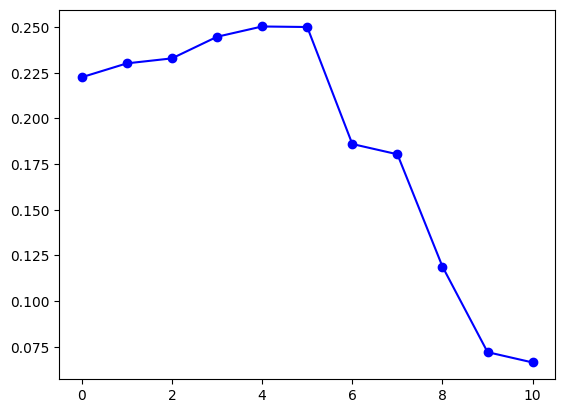

In [166]:
# Try to choose good cutoff - 0.7
acc_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
pr_auc_scores = []

model.fit(X_train, y_train)

for cutoff in np.arange(0.5, 0.92, 0.04):
  prob = model.predict_proba(X_test)[:, 1]
  pred = (prob >= cutoff).astype(int)

  acc_scores.append(accuracy_score(y_test, pred))
  precision_scores.append(precision_score(y_test, pred, zero_division=0))
  recall_scores.append(recall_score(y_test, pred, zero_division=0))
  f1_scores.append(f1_score(y_test, pred, zero_division=0))
  pr_auc_scores.append(average_precision_score(y_test, prob))

plt.plot(f1_scores, marker='o', linestyle='-', color='b')

In [167]:
# Train model and predict
model.fit(X_train, y_train)

# pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.7).astype(int)

In [168]:
# Evaluate
print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, prob):.4f}")

Accuracy:  0.8346
Precision: 0.1717
Recall:    0.4595
F1-score:  0.2500
PR-AUC:    0.1587


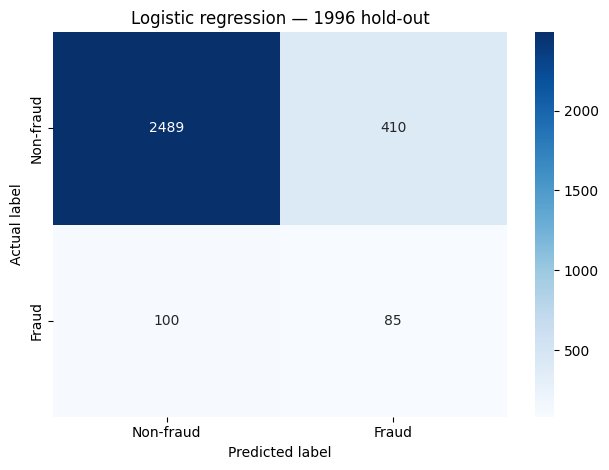

Correctly identified non-fraud: 2489
False alarms: 410
Missed fraud: 100
Fraud cases caught: 85


In [169]:
matrix = confusion_matrix(y_test, pred, labels=[0, 1])

sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)

### Logistic Regression (temporal holdout)

- Train on 1994, test on 1995
- Also great performance!!
- Seems like a good set of features to use

In [170]:
# Split - train on 1994, test on 1995
train = filtered_df.loc[filtered_df['Year'] == 1994, :]
test = filtered_df.loc[filtered_df['Year'] == 1995, :]

In [171]:
X_train = train.drop(columns = ['Year', 'FraudFound_P'])
y_train = train['FraudFound_P']
X_test = test.drop(columns = ['Year', 'FraudFound_P'])
y_test = test['FraudFound_P']

In [172]:
# Identify feature types
numeric_cols = X_train.select_dtypes(
  include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
  include=["object"]
).columns.tolist()

In [173]:
# Numeric columns: scale
numeric_pipeline = Pipeline([
  ("scaler", StandardScaler())
])

# Categorical columns: one-hot encode
categorical_pipeline = Pipeline([
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [174]:
# Apply the appropriate transformations
preprocessor = ColumnTransformer([
  ("numeric", numeric_pipeline, numeric_cols),
  ("categorical", categorical_pipeline, categorical_cols)
])

In [175]:
# Combine preprocessing and logistic regression
model = Pipeline([
  ("preprocessor", preprocessor),
  ("logistic", LogisticRegression(
    max_iter = 3000,
    class_weight = "balanced",
    random_state = 42
  ))
])

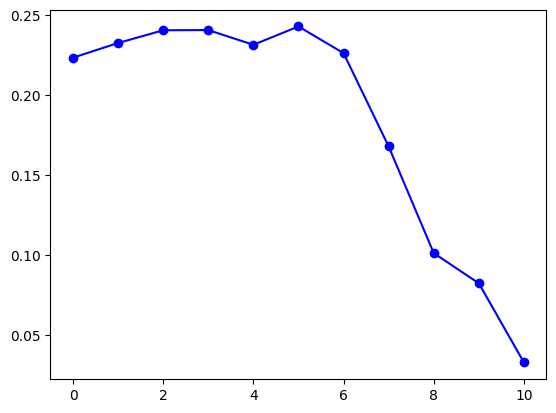

In [176]:
# Try to choose good cutoff - 0.7
acc_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
pr_auc_scores = []

model.fit(X_train, y_train)

for cutoff in np.arange(0.5, 0.92, 0.04):
  prob = model.predict_proba(X_test)[:, 1]
  pred = (prob >= cutoff).astype(int)

  acc_scores.append(accuracy_score(y_test, pred))
  precision_scores.append(precision_score(y_test, pred, zero_division=0))
  recall_scores.append(recall_score(y_test, pred, zero_division=0))
  f1_scores.append(f1_score(y_test, pred, zero_division=0))
  pr_auc_scores.append(average_precision_score(y_test, prob))

plt.plot(f1_scores, marker='o', linestyle='-', color='b')

In [177]:
# Train model and predict
model.fit(X_train, y_train)

# pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.7).astype(int)

In [178]:
# Evaluate
print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, prob):.4f}")

Accuracy:  0.8370
Precision: 0.1663
Recall:    0.4518
F1-score:  0.2431
PR-AUC:    0.1424


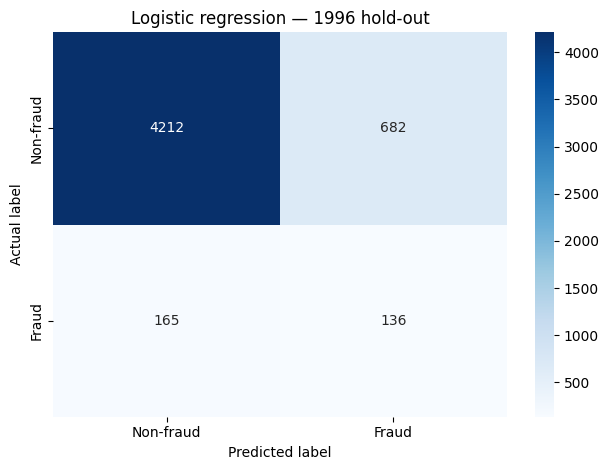

Correctly identified non-fraud: 4212
False alarms: 682
Missed fraud: 165
Fraud cases caught: 136


In [179]:
matrix = confusion_matrix(y_test, pred, labels=[0, 1])

sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)